In [18]:
import numpy as np
from spidercat.utils import load_solution_triplet
from spidercat.spanning_tree import match_forest_leaves_to_marked_edges, inject_root_nodes
from spidercat.circuit_extraction import expand_graph_and_forest
from spidercat.fault_analysis import compute_boundary_fault_table, build_graph_dem
from spidercat.draw import draw_forest_on_graph

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


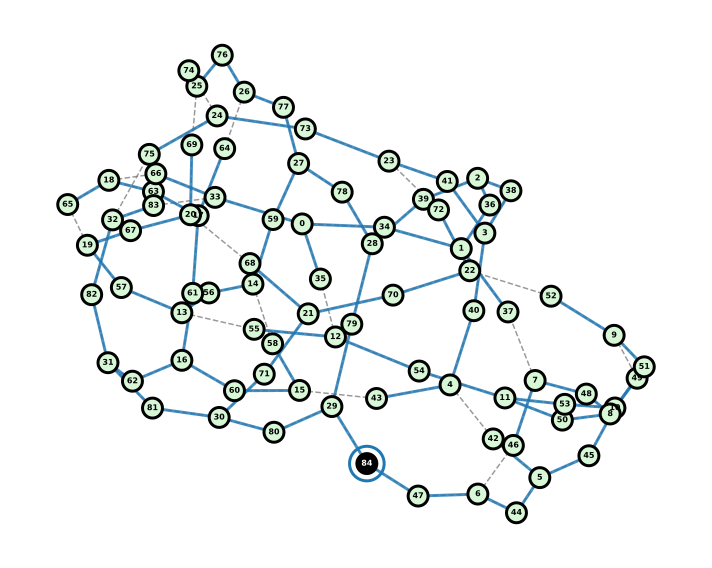

In [15]:
grf, forest, M, matchings = load_solution_triplet(50, 3, 1)
matchings = match_forest_leaves_to_marked_edges(grf, forest, M)
G_exp, F_exp = expand_graph_and_forest(grf, forest, M, matchings)
roots = inject_root_nodes(G_exp, F_exp)
draw_forest_on_graph(G_exp, F_exp, roots)

In [25]:
dem = build_graph_dem(G_exp, F_exp, root=roots[0], cycle_basis_mode="fundamental")
for e in dem.edges:
    detectors, logicals = dem.edge_targets(e)
    print(f"Edge {e}: D{detectors}, L{logicals}")

Edge (0, 33): D[8, 17], L[32]
Edge (0, 34): D[4, 8, 17], L[1, 32]
Edge (0, 35): D[4], L[1]
Edge (1, 34): D[4, 8, 17], L[0, 1, 32]
Edge (1, 36): D[2, 4, 8, 17], L[0, 1, 3, 32]
Edge (1, 37): D[2], L[3]
Edge (2, 36): D[2, 4, 8, 17], L[0, 1, 2, 3, 32]
Edge (2, 38): D[0, 7, 12, 13, 16], L[4, 6, 7, 9, 39, 41]
Edge (2, 39): D[0, 2, 4, 7, 8, 12, 13, 16, 17], L[0, 1, 2, 3, 4, 6, 7, 9, 32, 39, 41]
Edge (3, 38): D[0, 7, 12, 13, 16], L[6, 7, 9, 39, 41]
Edge (3, 40): D[0, 7], L[6, 9]
Edge (3, 41): D[12, 13, 16], L[7, 39, 41]
Edge (4, 40): D[0, 7], L[9]
Edge (4, 43): D[7], L[9]
Edge (5, 42): D[0], L[8]
Edge (5, 44): D[0, 1, 2, 4, 5, 11], L[8, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21]
Edge (5, 45): D[1, 2, 4, 5, 11], L[11, 12, 14, 15, 16, 17, 18, 19, 20, 21]
Edge (6, 44): D[0, 1, 2, 4, 5, 11], L[8, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21]
Edge (6, 47): D[0, 2, 4, 5, 11], L[8, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21]
Edge (7, 46): D[1], L[12]
Edge (7, 48): D[1, 2], L[12]
Edge (8, 48): D[1, 2], L[1

In [16]:
# 1. Precompute undetectable fault table up to boundary weight L=5
table = compute_boundary_fault_table(G_exp, F_exp, L=5, root=roots)
print(table.count_fault_sets())  # {1: 11, 2: 55, 3: 171, 4: 429, 5: 1142}

{1: 50, 2: 1225, 3: 19633, 4: 232049, 5: 2164381}


In [17]:
# 2. Substitute edge weights (dict, 1D array, or 2D batch array of optimization candidates)
weights = {e: 2 for e in table.dem.edges}
coeffs = table.evaluate_polynomial(weights)
print(table.format_polynomial(weights))

100p + 4900p^2 + 157064p^3 + 3712784p^4 + 69259360p^5
